# Step 4 — 스태킹 앙상블 (Stacking Ensemble)

- **목적 (Objective)**: 베이스 모델들의 OOF 예측을 입력으로 메타 모델을 학습해 `lgbm_tuned` (OOF `0.95986`) 초과.
- **전제**: 모든 베이스 모델이 **동일한 Fold 계약**(§3-1)으로 생성되었음. 본 노트북 첫 셀에서 재검증한다.

### 왜 OOF여야 하는가 (Why Out-of-Fold)

메타 모델은 "베이스 모델이 **학습에 쓰지 않은** 데이터에 대해 낸 예측"으로 학습해야 한다.
train 전체를 재예측한 in-fold 값은 자기 학습 데이터를 맞힌 것이라 과대평가되고,
메타 모델이 "이 베이스 모델은 거의 틀리지 않는다"고 잘못 학습한다.
OOF는 각 행이 **그 행을 보지 않은** 모델에서 나왔으므로 test에서 겪을 상황과 통계적으로 같다.

### 설계상의 두 가지 함정과 대응

| 함정 | 내용 | 대응 |
|---|---|---|
| **메타 CV 누수** | 메타 모델을 새 분할로 CV하면 베이스가 그 행을 학습했는지 알 수 없다 | 베이스와 **동일한 `fold` 컬럼**으로만 CV |
| **OOF ↔ Test 분포 차이** | OOF는 1개 모델 예측, test는 5개 모델 평균이라 분산이 다르다 | **순위 정규화(rank → [0,1])** 입력을 병행 비교. 순위 변환은 스케일 변화에 강건 |

### 사전 확인된 사실 (Step 3 블렌드 탐색)

동일 가중 rank-average는 `lgbm_tuned` 단독을 **넘지 못했다** (예: +`mlp` → 0.95935).
약한 모델(`mlp` 0.95730)에 동등 가중치를 주면 강한 모델을 끌어내리기 때문이다.
→ **가중치를 학습하는 메타 모델이 필요하다**는 것이 본 단계의 출발점이다.

### 낙관 편향 가드 (§1-5 A)

`mlp` 의 OOF는 **에폭 argmax 선택**으로 `lgbm` 계열보다 더 부풀려져 있다.
메타 모델이 `mlp` 에 단독 성능 대비 과도한 가중치를 주면 **학습된 스태커를 버리고 단순 평균을 채택**한다.

---

## 1. 베이스 모델 적재 및 Fold 계약 검증

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logit
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import roc_auc_score

SEED = 42
START_TIME = time.time()
COLOR_MAIN, COLOR_ALT, COLOR_MUTED = "#2a78d6", "#eb6834", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold",
})
print("ready")

ready


In [2]:
REQUIRED_FILES = ["train.csv", "test.csv", "sample_submission.csv"]
has_all = lambda f: all((f / n).is_file() for n in REQUIRED_FILES)
kaggle = Path("/kaggle/input")
cands = (sorted({p.parent for p in kaggle.glob("**/train.csv") if has_all(p.parent)}) if kaggle.exists()
         else list(dict.fromkeys(p.resolve() for p in (Path("data"), Path("../data")) if has_all(p))))
DATA_DIR = cands[0]
OUT_DIR = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = OUT_DIR / "predictions"      # 모델별 OOF / Test 예측 (§3-2 산출물 계약)
REPORT_DIR = OUT_DIR / "reports"        # 실험 요약 · 탐색 로그
for _d in (PRED_DIR, REPORT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
TARGET = "satisfaction"
y = train[TARGET].astype(int).values

# 사용 가능한 베이스 모델 자동 탐지 (oof_*.csv 와 test_*.csv 가 쌍으로 존재하는 것만)
CANDIDATES = ["lgbm_tuned", "lgbm_fe", "lgbm", "cat", "xgb", "mlp"]
BASES = [n for n in CANDIDATES
         if (PRED_DIR / f"oof_{n}.csv").exists() and (PRED_DIR / f"test_{n}.csv").exists()]
print("베이스 모델:", BASES)

oof_frames, test_frames, fold_ref = {}, {}, None
for n in BASES:
    d = pd.read_csv(PRED_DIR / f"oof_{n}.csv").sort_values("id").reset_index(drop=True)
    t = pd.read_csv(PRED_DIR / f"test_{n}.csv").sort_values("id").reset_index(drop=True)
    assert len(d) == len(train) and len(t) == len(test), f"{n}: 행 수 불일치"
    assert (d["id"].values == np.sort(train["id"].values)).all(), f"{n}: id 불일치"
    if fold_ref is None:
        fold_ref = d["fold"].values
    assert (d["fold"].values == fold_ref).all(), f"{n}: ★ Fold 계약 불일치 — 스태킹 불가"
    oof_frames[n], test_frames[n] = d["pred"].values, t["pred"].values

fold = fold_ref
N_FOLDS = fold.max() + 1
# train 을 id 정렬 기준으로 맞춘 타깃
order = np.argsort(train["id"].values)
y = y[order]
print(f"Fold 계약 검증 PASS — 전 모델 {len(train):,}행 fold 일치, {N_FOLDS} folds")

OOF = pd.DataFrame(oof_frames)
TEST = pd.DataFrame(test_frames)
solo = OOF.apply(lambda c: roc_auc_score(y, c)).sort_values(ascending=False)
print("\n단독 OOF AUC:")
print(solo.round(5).to_string())
CHAMP = solo.max()
CHAMP_NAME = solo.idxmax()

베이스 모델: ['lgbm_tuned', 'lgbm_fe', 'lgbm', 'cat', 'xgb', 'mlp']


Fold 계약 검증 PASS — 전 모델 699,635행 fold 일치, 5 folds



단독 OOF AUC:
lgbm_tuned    0.95986
cat           0.95935
lgbm_fe       0.95934
xgb           0.95929
lgbm          0.95866
mlp           0.95730


## 2. 메타 피처 표현 (Meta-Feature Representations)

세 가지 표현을 비교한다. 선형 메타 모델은 입력 표현에 민감하다.

| 표현 | 정의 | 특징 |
|---|---|---|
| `prob` | 원 확률값 | 기준 |
| `logit` | $\log\frac{p}{1-p}$ | 0/1 근처에서 포화된 확률을 선형 영역으로 펼침 |
| `rank` | 열별 순위 → $[0,1]$ | **OOF↔Test 분포 차이에 강건**. AUC가 순위 지표이므로 정보 손실 없음 |

**중요**: `rank` 변환은 OOF와 test를 **각각 독립적으로** 수행한다.
두 집합을 합쳐 순위를 매기면 test 정보가 학습에 새어든다.

In [3]:
EPS = 1e-6


def to_rank(df):
    return df.apply(lambda c: rankdata(c) / (len(c) + 1))


REPR = {
    "prob": (OOF.copy(), TEST.copy()),
    "logit": (OOF.clip(EPS, 1 - EPS).apply(logit), TEST.clip(EPS, 1 - EPS).apply(logit)),
    "rank": (to_rank(OOF), to_rank(TEST)),   # OOF / TEST 각각 독립 변환 (누수 방지)
}
for k, (a, b) in REPR.items():
    print(f"{k:6s} OOF range [{a.values.min():.3f}, {a.values.max():.3f}]  "
          f"TEST range [{b.values.min():.3f}, {b.values.max():.3f}]")

prob   OOF range [0.000, 1.000]  TEST range [0.001, 0.999]
logit  OOF range [-9.437, 7.804]  TEST range [-7.096, 6.791]
rank   OOF range [0.000, 1.000]  TEST range [0.000, 1.000]


## 3. 메타 모델 교차검증 (Meta-Model CV)

- **베이스와 동일한 `fold` 컬럼**으로 CV한다. 새 분할을 만들면 누수가 생긴다.
- fold $k$ 의 메타 예측은 **fold $\ne k$ 행으로 학습한** 메타 모델이 낸 값이다.
- Test 예측은 5개 fold 메타 모델의 평균.

In [4]:
def meta_cv(Xo, Xt, model_fn, use_proba=True):
    """베이스와 동일한 fold 로 메타 모델을 CV 하고 (oof, test, fold별 AUC) 를 반환."""
    oof = np.full(len(Xo), np.nan)
    test_pred = np.zeros(len(Xt))
    aucs = []
    for k in range(N_FOLDS):
        tr, va = fold != k, fold == k
        m = model_fn()
        m.fit(Xo[tr], y[tr])
        pred = m.predict_proba(Xo[va])[:, 1] if use_proba else m.predict(Xo[va])
        oof[va] = pred
        tp = m.predict_proba(Xt)[:, 1] if use_proba else m.predict(Xt)
        test_pred += tp / N_FOLDS
        aucs.append(roc_auc_score(y[va], oof[va]))
    return oof, test_pred, np.array(aucs)


def fit_coefs(Xo, model_fn):
    """전체 OOF로 1회 적합해 가중치를 해석용으로 추출."""
    m = model_fn()
    m.fit(Xo, y)
    return pd.Series(np.ravel(m.coef_), index=Xo.columns)


META = {
    "LogReg": (lambda: LogisticRegression(max_iter=2000, C=1.0), True),
    "LogReg (C=0.1)": (lambda: LogisticRegression(max_iter=2000, C=0.1), True),
}

results = []
for rname, (Xo, Xt) in REPR.items():
    Xo_v, Xt_v = Xo.values, Xt.values
    for mname, (fn, proba) in META.items():
        oof_p, test_p, aucs = meta_cv(Xo_v, Xt_v, fn, proba)
        results.append({"표현": rname, "메타": mname, "OOF": roc_auc_score(y, oof_p),
                        "folds": aucs, "oof_vec": oof_p, "test_vec": test_p, "Xo": Xo})
        print(f"{rname:6s} {mname:16s} OOF = {results[-1]['OOF']:.5f}  "
              f"folds {aucs.round(5).tolist()}", flush=True)

prob   LogReg           OOF = 0.95980  folds [0.96007, 0.9588, 0.96065, 0.95978, 0.9599]


prob   LogReg (C=0.1)   OOF = 0.95978  folds [0.96004, 0.95882, 0.96059, 0.95978, 0.95991]


logit  LogReg           OOF = 0.95994  folds [0.96022, 0.9589, 0.96074, 0.95995, 0.96]


logit  LogReg (C=0.1)   OOF = 0.95994  folds [0.96022, 0.9589, 0.96075, 0.95994, 0.96]


rank   LogReg           OOF = 0.95968  folds [0.95999, 0.95871, 0.96047, 0.95961, 0.95981]


rank   LogReg (C=0.1)   OOF = 0.95969  folds [0.96, 0.95872, 0.96048, 0.95962, 0.95981]


In [5]:
# 비교 하한선: 동일 가중 rank-average (전 모델 / lgbm계열 제외)
rank_all = to_rank(OOF).mean(axis=1).values
rank_all_t = to_rank(TEST).mean(axis=1).values
baseline_blend = roc_auc_score(y, rank_all)

summary = pd.DataFrame([{"구성": f"{r['표현']} + {r['메타']}", "OOF": round(r["OOF"], 5),
                         "Δ vs champion": round(r["OOF"] - CHAMP, 5)} for r in results])
summary = pd.concat([
    pd.DataFrame([{"구성": f"{CHAMP_NAME} 단독 (champion)", "OOF": round(CHAMP, 5), "Δ vs champion": 0.0},
                  {"구성": "동일가중 rank-average (전 모델)", "OOF": round(baseline_blend, 5),
                   "Δ vs champion": round(baseline_blend - CHAMP, 5)}]),
    summary], ignore_index=True).sort_values("OOF", ascending=False)
print(summary.to_string(index=False))

                      구성     OOF  Δ vs champion
          logit + LogReg 0.95994        0.00008
  logit + LogReg (C=0.1) 0.95994        0.00008
lgbm_tuned 단독 (champion) 0.95986        0.00000
동일가중 rank-average (전 모델) 0.95981       -0.00005
           prob + LogReg 0.95980       -0.00006
   prob + LogReg (C=0.1) 0.95978       -0.00007
   rank + LogReg (C=0.1) 0.95969       -0.00017
           rank + LogReg 0.95968       -0.00018


## 4. 가중치 해석 및 낙관 편향 가드 (Weight Inspection & Optimism Guard)

메타 모델이 각 베이스에 부여한 가중치를 확인한다.
§1-5 A에 따라 `mlp` 는 OOF가 부풀려져 있으므로, **단독 성능 순위에 비해 과도한 가중치**를 받으면
학습된 스태커를 신뢰하지 않고 단순 평균을 채택한다.

In [6]:
best = max(results, key=lambda r: r["OOF"])
print(f"최고 구성: {best['표현']} + {best['메타']}  OOF = {best['OOF']:.5f}\n")

fn = META[best["메타"]][0]
coefs = fit_coefs(best["Xo"], fn)
w = pd.DataFrame({"계수": coefs, "단독 OOF": solo.reindex(coefs.index)})
w["계수 순위"] = w["계수"].rank(ascending=False).astype(int)
w["성능 순위"] = w["단독 OOF"].rank(ascending=False).astype(int)
w["순위 괴리"] = w["성능 순위"] - w["계수 순위"]
print(w.round(5).to_string())

mlp_gap = int(w.loc["mlp", "순위 괴리"]) if "mlp" in w.index else 0
guard_trip = mlp_gap >= 2
print(f"\nmlp 순위 괴리 = {mlp_gap}  (성능 {w.loc['mlp', '성능 순위'] if 'mlp' in w.index else '-'}위 → "
      f"가중치 {w.loc['mlp', '계수 순위'] if 'mlp' in w.index else '-'}위)")
print(f"가드 발동: {'⚠️ 예 — 단순 평균 검토' if guard_trip else '아니오'}")

최고 구성: logit + LogReg (C=0.1)  OOF = 0.95994



                 계수   단독 OOF  계수 순위  성능 순위  순위 괴리
lgbm_tuned  0.59827  0.95986      1      1      0
lgbm_fe     0.24595  0.95934      2      3      1
lgbm       -0.19847  0.95866      6      5     -1
cat         0.18040  0.95935      3      2     -1
xgb         0.01206  0.95929      5      4     -1
mlp         0.16685  0.95730      4      6      2

mlp 순위 괴리 = 2  (성능 6위 → 가중치 4위)
가드 발동: ⚠️ 예 — 단순 평균 검토


/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_83881/259957828.py:22: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_83881/259957828.py:22: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_83881/259957828.py:22: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_83881/259957828.py:22: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/q7/ns6nlfjd3gdgf4s1h0p6gbmm0000gn/T/ipykernel_83881/259957828.py:22: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()

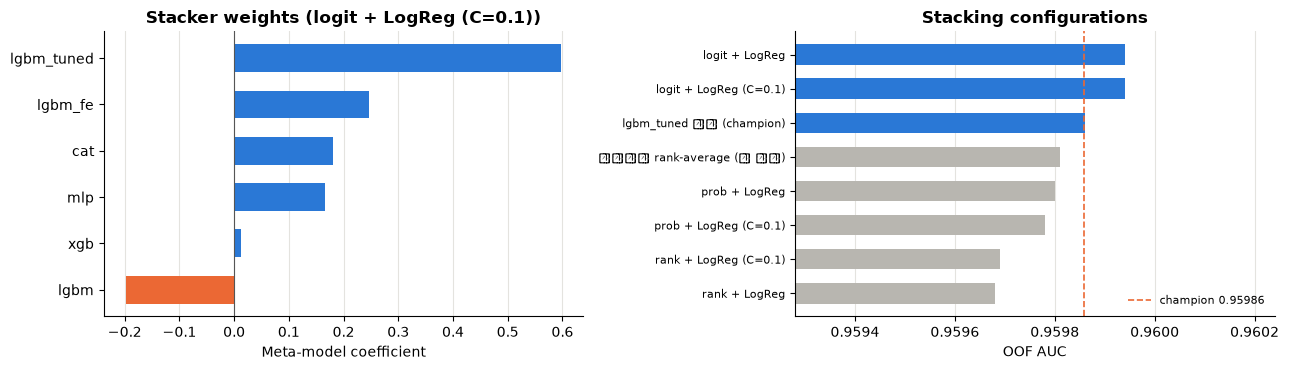

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

order_w = coefs.sort_values()
axes[0].barh(order_w.index, order_w.values, height=0.6,
             color=[COLOR_ALT if v < 0 else COLOR_MAIN for v in order_w.values])
axes[0].axvline(0, color="#555", linewidth=0.8)
axes[0].set_xlabel("Meta-model coefficient")
axes[0].set_title(f"Stacker weights ({best['표현']} + {best['메타']})")
axes[0].grid(axis="y", visible=False)

lbl = list(summary["구성"])[::-1]
val = list(summary["OOF"])[::-1]
axes[1].barh(lbl, val, height=0.6,
             color=[COLOR_MAIN if v >= CHAMP else COLOR_MUTED for v in val])
axes[1].axvline(CHAMP, color=COLOR_ALT, linestyle="--", linewidth=1.2, label=f"champion {CHAMP:.5f}")
axes[1].set_xlim(min(val) - 0.0004, max(val) + 0.0003)
axes[1].set_xlabel("OOF AUC")
axes[1].set_title("Stacking configurations")
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## 5. 최종 판정 및 제출 파일 생성 (Decision & Submission)

- 채택 기준(§3-4): champion 대비 **pooled OOF 개선** 且 **4/5 Fold 이상 개선**.
- 가드 발동 시 학습된 스태커 대신 단순 평균을 검토한다.
- 제출 파일은 §3-3 assert 블록을 전부 통과해야 하며, `chacha/` 안에 점수를 포함한 이름으로 저장한다.

In [8]:
champ_oof = OOF[CHAMP_NAME].values
champ_folds = np.array([roc_auc_score(y[fold == k], champ_oof[fold == k]) for k in range(N_FOLDS)])

cand = {"stacker": (best["oof_vec"], best["test_vec"], best["folds"]),
        "rank-average": (rank_all, rank_all_t,
                         np.array([roc_auc_score(y[fold == k], rank_all[fold == k]) for k in range(N_FOLDS)]))}

rows = []
for name, (o, t, f) in cand.items():
    pooled = roc_auc_score(y, o)
    wins = int((f > champ_folds).sum())
    rows.append({"후보": name, "OOF": round(pooled, 5), "Δ": round(pooled - CHAMP, 5),
                 "fold 개선": f"{wins}/5", "채택 가능": (pooled > CHAMP) and (wins >= 4)})
decision = pd.DataFrame(rows)
print(f"champion({CHAMP_NAME}) folds = {champ_folds.round(5).tolist()}\n")
print(decision.to_string(index=False))

eligible = [r for r in rows if r["채택 가능"]]
if guard_trip and any(r["후보"] == "rank-average" and r["채택 가능"] for r in rows):
    pick = "rank-average"
    print("\n⚠️ 가드 발동 → 단순 평균 채택")
elif eligible:
    pick = max(eligible, key=lambda r: r["OOF"])["후보"]
else:
    pick = None

if pick:
    final_oof, final_test, _ = cand[pick]
    FINAL_NAME, FINAL_AUC = pick, roc_auc_score(y, final_oof)
else:
    final_oof, final_test = champ_oof, TEST[CHAMP_NAME].values
    FINAL_NAME, FINAL_AUC = CHAMP_NAME, CHAMP
print(f"\n최종 선택: {FINAL_NAME}   OOF = {FINAL_AUC:.5f}")

champion(lgbm_tuned) folds = [0.96009, 0.95869, 0.96064, 0.95996, 0.95998]

          후보     OOF        Δ fold 개선  채택 가능
     stacker 0.95994  0.00008     4/5   True
rank-average 0.95981 -0.00005     1/5  False

최종 선택: stacker   OOF = 0.95994


In [9]:
# --- §3-3 제출 파일 계약 ---
test_ids = np.sort(test["id"].values)
pred_df = pd.DataFrame({"id": test_ids, TARGET: final_test})

assert pred_df["id"].is_unique
assert set(pred_df["id"]) == set(sample["id"])
submission = sample[["id"]].merge(pred_df, on="id", how="left", validate="one_to_one")
assert len(submission) == len(sample)
assert (submission["id"].values == sample["id"].values).all()
assert submission[TARGET].notna().all()
assert submission[TARGET].between(0, 1).all()

out_name = f"submission_{FINAL_NAME.replace(' ', '')}_{FINAL_AUC:.5f}.csv"
submission.to_csv(out_name, index=False)
print(f"저장: {Path(out_name).resolve()}")
print(f"shape {submission.shape}  |  pred range [{submission[TARGET].min():.4f}, {submission[TARGET].max():.4f}]")
print(submission.head().to_string(index=False))

if FINAL_NAME == "stacker":
    pd.DataFrame({"id": np.sort(train["id"].values), "fold": fold, "pred": final_oof}).to_csv(PRED_DIR / "oof_stack.csv", index=False)
    pd.DataFrame({"id": test_ids, "pred": final_test}).to_csv(PRED_DIR / "test_stack.csv", index=False)
    print("saved oof_stack.csv / test_stack.csv")
summary.to_csv(REPORT_DIR / "step4_summary.csv", index=False)
print(f"\n전체 실행 시간: {time.time() - START_TIME:.0f}초")

저장: /Users/chanjong/sesac-ai/중간평가/chacha/submission_stacker_0.95994.csv
shape (299844, 2)  |  pred range [0.0015, 0.9954]
    id  satisfaction
699635      0.222640
699636      0.868722
699637      0.917751
699638      0.061725
699639      0.038498


saved oof_stack.csv / test_stack.csv

전체 실행 시간: 12초
